Supply Chain EDA Project
### EXecutive Summery -Revenue ,profit ,delivery , stock

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
xls = pd.ExcelFile("Supply_Chain_Dataset.xlsx")
print(xls.sheet_names)

orders = pd.read_excel(xls, "Orders")
products = pd.read_excel(xls, "Products")
shipments = pd.read_excel(xls, "Shipments")
inventory = pd.read_excel(xls, "Inventory")

orders.head()

['Orders', 'Products', 'Suppliers', 'Warehouses', 'Shipments', 'Inventory']


,order_id,order_date,customer_id,product_id,quantity,unit_price,region,warehouse_id,order_status,promised_days,promised_delivery_date,actual_delivery_date,revenue
0,ORD004016,2023-05-05,CUST00656,P0116,4,3745.61,North,WH05,Cancelled,8,2023-05-13,NaT,14982.44
1,ORD003528,2023-05-27,CUST00937,P0113,12,6003.39,North,WH05,In Transit,4,2023-05-31,NaT,72040.68
2,ORD001421,2023-01-24,CUST00306,P0107,12,641.51,East,WH03,Cancelled,3,2023-01-27,NaT,7698.12
3,ORD001353,2024-11-15,CUST00765,P0107,13,631.21,West,WH03,Delivered,9,2024-11-24,2024-11-30,8205.73
4,ORD003126,2023-03-07,CUST00673,P0049,1,743.06,North,WH02,Delivered,5,2023-03-12,2023-03-05,743.06


In [3]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\scs
['.anaconda', '.bash_history', '.conda', '.continuum', '.copilot', '.idlerc', '.ipynb_checkpoints', '.ipython', '.jupyter', '.virtual_documents', '.vscode', '.vscode-shared', '3D Objects', 'anaconda3', 'anaconda_projects', 'AppData', 'Application Data', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'india-sales-data-analysis', 'IntelGraphicsProfiles', 'Links', 'Local Settings', 'Microsoft', 'Music', 'My Documents', 'my first project', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TM.blf', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'PrintHood', 'python basics assign. no.1', 'PYTHON TEST 3', 'Recent', 'Saved Games', 'Searches', 'SendTo', 'smart traffic final.ipynb', 'Smart Traffic fine mang. system project', 'S

In [4]:
import pandas as pd
xls = pd.ExcelFile(r"C:\Users\scs\Downloads\Supply_Chain_Dataset.xlsx", engine="openpyxl")
print(xls.sheet_names)

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\scs\\Downloads\\Supply_Chain_Dataset.xlsx'

In [ ]:
import pandas as pd

xls = pd.ExcelFile(r"C:\Users\scs\OneDrive\Documents\supply_chain_dataset.xlsx", engine="openpyxl")
print(xls.sheet_names)

orders = pd.read_excel(xls, "Orders", engine="openpyxl")
orders.head()

In [ ]:
products = pd.read_excel(xls, "Products", engine="openpyxl")
suppliers = pd.read_excel(xls, "Suppliers", engine="openpyxl")
warehouses = pd.read_excel(xls, "Warehouses", engine="openpyxl")
shipments = pd.read_excel(xls, "Shipments", engine="openpyxl")
inventory = pd.read_excel(xls, "Inventory", engine="openpyxl")

 
print("Orders:", orders.shape)
print("Products:", products.shape)
print("Suppliers:", suppliers.shape)
print("Warehouses:", warehouses.shape)
print("Shipments:", shipments.shape)
print("Inventory:", inventory.shape)

In [ ]:
print("Orders columns:")
print(orders.columns.tolist())
print("\nProducts columns:")
print(products.columns.tolist())
print("\nShipments columns:")
print(shipments.columns.tolist())
print("\nInventory columns:")
print(inventory.columns.tolist())

In [ ]:
print("Orders missing:")
print(orders.isnull().sum())
print("\nShipments missing:")
print(shipments.isnull().sum())
print("\nInventory missing:")
print(inventory.isnull().sum())

In [ ]:
print("\nOrders duplicate:", orders.duplicated().sum())
print("Shipments duplicate:", shipments.duplicated().sum())

In [ ]:
print(orders['order_status'].value_counts())
print("\n")

In [ ]:
print("Before Orders:", orders.shape)
orders = orders.drop_duplicates()
print("After Orders:", orders.shape)

In [ ]:
orders['order_date'] = pd.to_datetime(orders['order_date'])
orders['promised_delivery_date'] = pd.to_datetime(orders['promised_delivery_date'])
orders['actual_delivery_date'] = pd.to_datetime(orders['actual_delivery_date'])
print("Done")
print(orders.dtypes)

In [ ]:
orders['unit_price'] = orders.groupby('product_id')['unit_price'].transform(lambda x: x.fillna(x.median()))
print("Missing unit_price:", orders['unit_price'].isnull().sum())

In [6]:
orders['delivery_delay_days'] = (orders['actual_delivery_date'] - orders['promised_delivery_date']).dt.days
orders['is_late'] = orders['delivery_delay_days'] > 0
print("Done")
print(orders[['delivery_delay_days', 'is_late']].head())

Done
   delivery_delay_days  is_late
0                  NaN    False
1                  NaN    False
2                  NaN    False
3                  6.0     True
4                 -7.0    False


In [7]:
delivered = orders[orders['order_status'] == 'Delivered']
print("Delivered total:", len(delivered))
print("Late %:", round(delivered['is_late'].mean()*100, 1))
print("Avg delay:", round(delivered['delivery_delay_days'].mean(), 1))

Delivered total: 2905
Late %: 54.8
Avg delay: 1.7


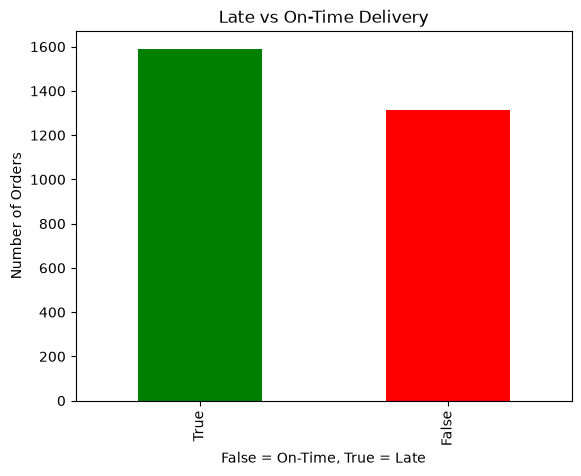

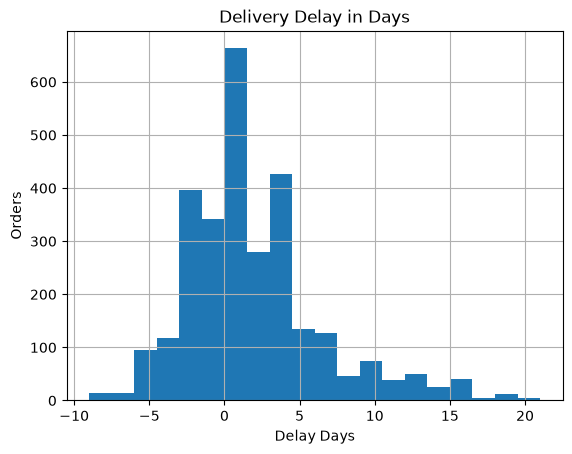

In [ ]:
import matplotlib.pyplot as plt

# 1. Late vs On-Time Graph
delivered['is_late'].value_counts().plot(kind='bar', color=['green', 'red'])
plt.title('Late vs On-Time Delivery')
plt.xlabel('False = On-Time, True = Late')
plt.ylabel('Number of Orders')
plt.show()


delivered['delivery_delay_days'].hist(bins=20)
plt.title('Delivery Delay in Days')
plt.xlabel('Delay Days')
plt.ylabel('Orders')
plt.show()

In [9]:
late_by_mode = delivered.groupby('Shipping Mode')['is_late'].mean() * 100

late_by_mode.plot(kind='bar', color='orange')
plt.title('Late % by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Late %')
plt.xticks(rotation=0)
plt.show()

print(late_by_mode)

KeyError: 'Shipping Mode'

In [10]:
print(delivered.columns.tolist())

['order_id', 'order_date', 'customer_id', 'product_id', 'quantity', 'unit_price', 'region', 'warehouse_id', 'order_status', 'promised_days', 'promised_delivery_date', 'actual_delivery_date', 'revenue', 'delivery_delay_days', 'is_late']


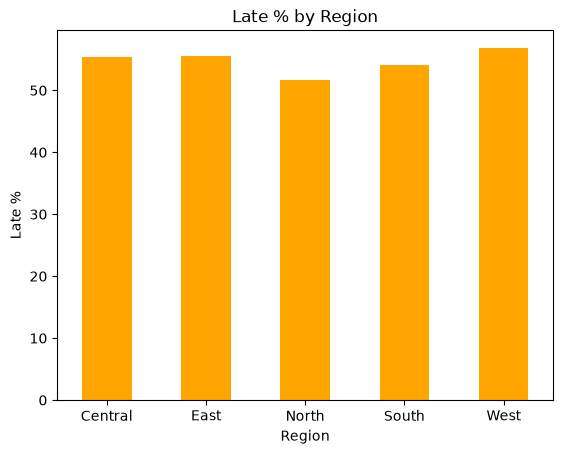

region
Central    55.405405
East       55.593220
North      51.642336
South      54.123711
West       56.829680
Name: is_late, dtype: float64


In [11]:
late_by_region = delivered.groupby('region')['is_late'].mean() * 100

late_by_region.plot(kind='bar', color='orange')
plt.title('Late % by Region')
plt.xlabel('Region')
plt.ylabel('Late %')
plt.xticks(rotation=0)
plt.show()

print(late_by_region)

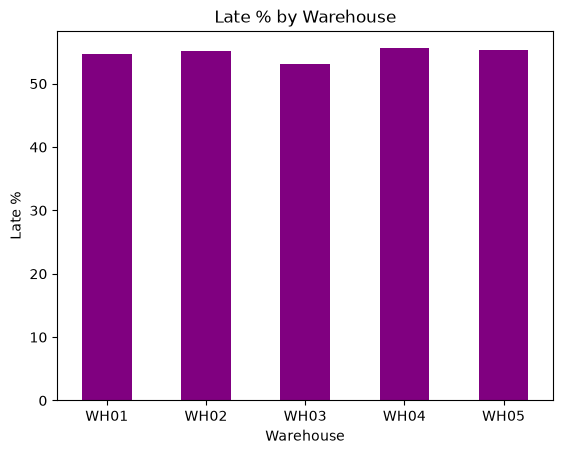

warehouse_id
WH01    54.713805
WH02    55.154639
WH03    53.071672
WH04    55.555556
WH05    55.373406
Name: is_late, dtype: float64


In [12]:
late_by_wh = delivered.groupby('warehouse_id')['is_late'].mean() * 100

late_by_wh.plot(kind='bar', color='purple')
plt.title('Late % by Warehouse')
plt.xlabel('Warehouse')
plt.ylabel('Late %')
plt.xticks(rotation=0)
plt.show()

print(late_by_wh)